# Learning $\sin(x)$ with a neural network
### DRP: a first example in function approximation

We will build a function $f_\theta(x)$ with adjustable parameters $\theta$ and train it to approximate $\sin(x)$ on $[0,\pi]$. All angles are in **radians**.

The order is **data → architecture → loss → training → testing**. We use PyTorch on the CPU, one hidden layer, and ordinary gradient descent. No prior PyTorch experience is assumed. Basic derivatives and the chain rule will help with the explanation.

Run the cells from top to bottom. To repeat the experiment, restart the kernel and run all cells so the network is initialized again. The saved notebook already contains the outputs. The `figures` folder receives the plots used by the Beamer slides.

**Setup:** install `torch`, `matplotlib`, and `ipykernel` in your Python environment (see `README.txt`). The fixed seed makes the starting weights repeatable in the same environment; small differences across versions or platforms are possible.

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(7)
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 12})

## 1. Create the training data

We sample 64 equally spaced inputs, including both endpoints of $[0,\pi]$, and calculate their targets $y_i=\sin(x_i)$.

`reshape(-1, 1)` gives one input per row: a tensor of shape `(64, 1)`. PyTorch layers expect a row for each example and a column for each input feature. We know the true function here, which lets us check our model exactly. In a real application, the targets might come from measurements.

In [2]:
x_train = torch.linspace(0, torch.pi, 64).reshape(-1, 1)
y_train = torch.sin(x_train)

The dots below are the examples used to adjust the parameters.

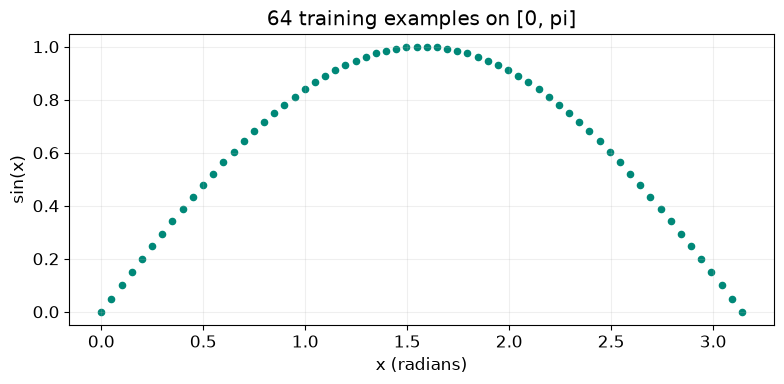

In [3]:
plt.scatter(x_train, y_train, s=20, color="#008878")
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.title("64 training examples on [0, pi]")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("figures/training_data.pdf")
plt.show()

## 2. Define the neural network

Our architecture has one input, **16 hidden neurons**, and one output:

$$h_j(x)=\tanh(w_jx+b_j),\qquad
f_\theta(x)=c+\sum_{j=1}^{16}v_jh_j(x).$$

The first `Linear` layer calculates the 16 values $w_jx+b_j$. `Tanh` applies the nonlinear function $\tanh$ to each value. The final `Linear` layer forms a weighted sum and adds the output bias $c$.

There are **49 trainable parameters**: 16 input weights $w_j$, 16 hidden biases $b_j$, 16 output weights $v_j$, and one output bias $c$. `Tanh` has no trainable parameters. A bias shifts a neuron's response; a weight controls how strongly a value contributes.

Without the nonlinear activation, composing these two linear layers would still give only an affine function $ax+b$. It could not capture the curved sine function. The output layer has no activation, so its output is not restricted to a fixed range.

In [4]:
model = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

We save the untrained predictions on a dense plotting grid so we can compare the curve before and after learning. `no_grad()` disables gradient tracking for this calculation.

In [5]:
x_plot = torch.linspace(0, torch.pi, 400).reshape(-1, 1)
with torch.no_grad():
    y_before = model(x_plot)

## 3. Define the loss and the update rule

The **mean squared error (MSE)** measures disagreement with the training targets:

$$L(\theta)=\frac{1}{64}\sum_{i=1}^{64}\left(f_\theta(x_i)-y_i\right)^2.$$

We minimize this loss by updating every parameter in the direction opposite its derivative:

$$\theta\leftarrow\theta-\eta\nabla_\theta L,\qquad \eta=0.05.$$

The **learning rate** $\eta$ controls the step size. The optimizer changes the weights and biases, while the number of neurons and the learning rate are choices we make in advance (hyperparameters).

PyTorch calls this optimizer `SGD`. Because we pass all 64 examples at every step, we are using **full-batch gradient descent**, without momentum. A step aims to lower the loss, but an overly large learning rate can make the loss increase.

In [6]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

## 4. Train the network

Each epoch uses all training examples once:

1. Clear gradients left over from the previous step with `zero_grad()`.
2. Evaluate the model and calculate the loss.
3. Use `backward()` to calculate derivatives by the chain rule (backpropagation).
4. Use `step()` to update the parameters.

`backward()` computes gradients; `step()` changes parameters. The gradients would accumulate if we did not reset them. `loss.item()` gives a plain number for plotting.

For one example, write $e=f_\theta(x)-y$ and $\ell=e^2$. The chain rule gives

$$\frac{\partial\ell}{\partial v_j}=2e h_j,\quad
\frac{\partial\ell}{\partial w_j}=2e v_j(1-h_j^2)x,\quad
\frac{\partial\ell}{\partial b_j}=2e v_j(1-h_j^2),\quad
\frac{\partial\ell}{\partial c}=2e.$$

The training loss averages these derivatives over all 64 examples. PyTorch performs these calculations automatically.

In [7]:
history = []
for epoch in range(10000):
    optimizer.zero_grad()
    loss = loss_fn(model(x_train), y_train)
    loss.backward()
    optimizer.step()
    history.append(loss.item())

The vertical axis is logarithmic: equal vertical distances represent equal ratios of loss. Entry 0 is the loss before the first update; the last entry is before update 10,000. A falling training loss shows an improved fit to the training examples, but does not by itself establish accuracy at new points.

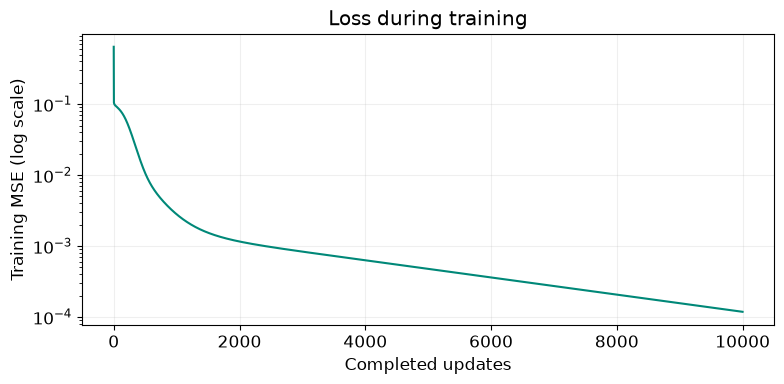

In [8]:
plt.semilogy(history, color="#008878")
plt.xlabel("Completed updates")
plt.ylabel("Training MSE (log scale)")
plt.title("Loss during training")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("figures/loss_curve.pdf")
plt.show()

We now evaluate the model after all 10,000 updates. `eval()` selects evaluation behavior; this particular network has no dropout or batch normalization, so its formula stays the same. `no_grad()` avoids building a gradient computation graph.

In [9]:
model.eval()
with torch.no_grad():
    y_after = model(x_plot)
    train_mse = loss_fn(model(x_train), y_train).item()
print(f"Final training MSE: {train_mse:.8f}")

Final training MSE: 0.00011814


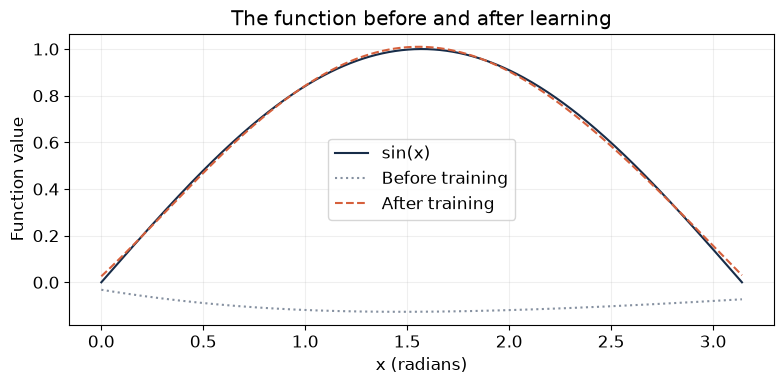

In [10]:
plt.plot(x_plot, torch.sin(x_plot), color="#172C48", label="sin(x)")
plt.plot(x_plot, y_before, ":", color="#8590A0", label="Before training")
plt.plot(x_plot, y_after, "--", color="#D6603C", label="After training")
plt.xlabel("x (radians)")
plt.ylabel("Function value")
plt.title("The function before and after learning")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("figures/learned_function.pdf")
plt.show()

## 5. Test on new inputs in $[0,\pi/2]$

We choose six points between 0 and $\pi/2\approx1.571$. None is on the training grid. We compute the predictions with the parameters fixed and compare them to the exact sine values.

This is a small **interpolation** check: the test inputs lie inside the training interval. It does not measure extrapolation outside $[0,\pi]$, and six points cannot certify accuracy everywhere. We use these points only for the final comparison, not for gradient updates or choosing training settings. If you tune settings using test results, reserve a fresh test set for your final evaluation.

In [11]:
x_test = torch.tensor([0.1, 0.3, 0.6, 0.9, 1.2, 1.5]).reshape(-1, 1)
y_test = torch.sin(x_test)
with torch.no_grad():
    y_pred = model(x_test)
error = (y_pred - y_test).abs()
test_mse = loss_fn(y_pred, y_test).item()

Absolute error is $|f_\theta(x)-\sin(x)|$. MSE averages the **squared** errors; it is different from the average absolute error.

In [12]:
print("   x       sin(x)    prediction   abs. error")
for x, y, p, e in zip(x_test, y_test, y_pred, error):
    print(f"{x.item():5.2f}    {y.item():8.5f}    {p.item():8.5f}    {e.item():8.5f}")
print(f"Test MSE: {test_mse:.8f}")
print(f"Maximum test absolute error: {error.max().item():.5f}")

   x       sin(x)    prediction   abs. error
 0.10     0.09983     0.11003     0.01019
 0.30     0.29552     0.28904     0.00648
 0.60     0.56464     0.55484     0.00980
 0.90     0.78333     0.78145     0.00188
 1.20     0.93204     0.93977     0.00774
 1.50     0.99749     1.00802     0.01053
Test MSE: 0.00006936
Maximum test absolute error: 0.01053


The left plot compares the six predictions with the true curve. The right plot magnifies their absolute errors. Even when two curves look identical, their values can differ.

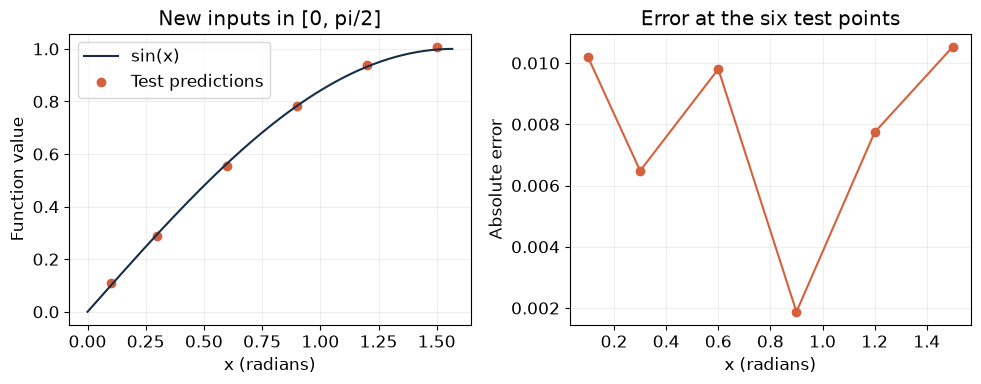

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
mask = x_plot[:, 0] <= torch.pi / 2
axes[0].plot(x_plot[mask], torch.sin(x_plot[mask]), color="#172C48", label="sin(x)")
axes[0].scatter(x_test, y_pred, color="#D6603C", label="Test predictions")
axes[0].set(xlabel="x (radians)", ylabel="Function value", title="New inputs in [0, pi/2]")
axes[0].legend()
axes[1].plot(x_test, error, "o-", color="#D6603C")
axes[1].set(xlabel="x (radians)", ylabel="Absolute error", title="Error at the six test points")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("figures/test_results.pdf")
plt.show()

## Discussion and experiments

- **What changed during training?** The 49 weights and biases changed. The examples, activation, and number of neurons stayed fixed.
- **Where is sine in the model?** We use sine to make labels and check results. The model itself is a sum of shifted and scaled $\tanh$ functions.
- **Why use a neural network when sine is known?** This is a controlled learning example. The sine formula is already the better way to calculate sine itself.
- **What happens without `nn.Tanh()`?** Predict the shape first, then remove it and rerun from the beginning.
- **How much training is needed?** Try 100 or 1,000 epochs and compare the training curve. Try changing 16 hidden neurons to 4 (in both linear layers).
- **What happens outside the training interval?** Extend the plotting grid to $[0,2\pi]$. Do not assume the network has learned sine's periodicity.

For an optional look at the learned numbers, evaluate `model[0].weight`, `model[0].bias`, `model[2].weight`, or `model[2].bias` in a new cell.

**Further reading:** PyTorch's [optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) explains the gradient-reset, backward-pass, and optimizer-step sequence. Its [automatic differentiation tutorial](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html) explains how PyTorch tracks derivatives.